## Practical 1 — Edge, Corner & Blob Detection
Problem:​
Take a suitable grayscale image containing objects with clear shapes and implement the
following using OpenCV:
1.​ Detect edges using Sobel in the X and Y directions.
2.​ Generate an edge image using Canny Edge Detection.
3.​ Detect corners using Harris Corner Detection.
4.​ Detect corners using Shi-Tomasi Corner Detection.
5.​ Detect blobs using LoG or DoG.
6.​ Display the original image and the outputs of each method.
7.​ Compare the results and write a short observation explaining which type of image
structure each method detects.

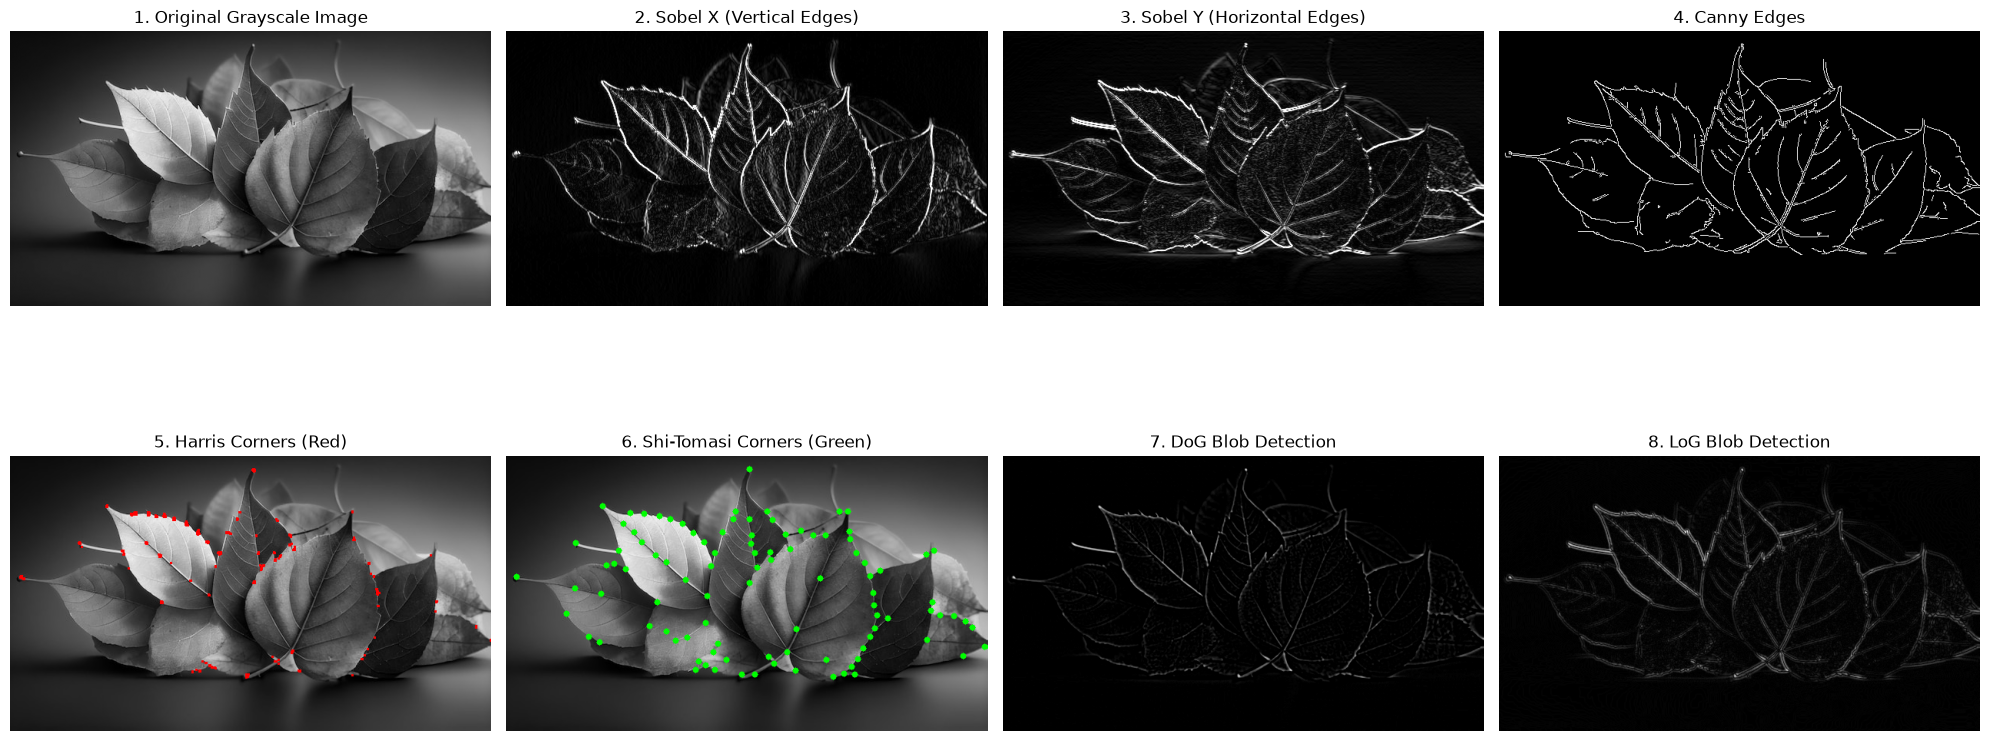

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img_gray = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

# Create RGB copies for colored visualization of corners
img_harris = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2RGB)
img_shi_tomasi = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2RGB)

# 1. Detect edges using Sobel in X and Y directions
sobel_x_64 = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y_64 = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)

sobel_x = cv2.convertScaleAbs(sobel_x_64)
sobel_y = cv2.convertScaleAbs(sobel_y_64)

# 2. Generate an edge image using Canny Edge Detection
canny_edges = cv2.Canny(img_gray, 100, 200)

# 3. Detect corners using Harris Corner Detection
gray_float = np.float32(img_gray)
harris_response = cv2.cornerHarris(gray_float, blockSize=2, ksize=3, k=0.04)
harris_response = cv2.dilate(harris_response, None)
img_harris[harris_response > 0.01 * harris_response.max()] = [255, 0, 0]

# 4. Detect corners using Shi-Tomasi Corner Detection
corners = cv2.goodFeaturesToTrack(gray_float, maxCorners=100, qualityLevel=0.01, minDistance=10)
if corners is not None:
    corners = np.int32(corners)
    for i in corners:
        x, y = i.ravel()
        cv2.circle(img_shi_tomasi, (x, y), radius=4, color=(0, 255, 0), thickness=-1)

#  Detect blobs using DoG (Difference of Gaussians)
blur1 = cv2.GaussianBlur(img_gray, (3, 3), 1.0)
blur2 = cv2.GaussianBlur(img_gray, (9, 9), 2.0)
dog_blobs = cv2.subtract(blur1, blur2)

#  Detect blobs using LoG (Laplacian of Gaussian)

gaussian_blur = cv2.GaussianBlur(img_gray, (5, 5), 0)
log_64 = cv2.Laplacian(gaussian_blur, cv2.CV_64F, ksize=3)
log_blobs = cv2.convertScaleAbs(log_64)


fig, axes = plt.subplots(2, 4, figsize=(20, 10))
ax = axes.ravel()

# Plot 1: Original Image
ax[0].imshow(img_gray, cmap='gray')
ax[0].set_title("1. Original Grayscale Image")
ax[0].axis('off')

# Plot 2: Sobel X
ax[1].imshow(sobel_x, cmap='gray')
ax[1].set_title("2. Sobel X (Vertical Edges)")
ax[1].axis('off')

# Plot 3: Sobel Y
ax[2].imshow(sobel_y, cmap='gray')
ax[2].set_title("3. Sobel Y (Horizontal Edges)")
ax[2].axis('off')

# Plot 4: Canny Edge Detection
ax[3].imshow(canny_edges, cmap='gray')
ax[3].set_title("4. Canny Edges")
ax[3].axis('off')

# Plot 5: Harris Corner Detection
ax[4].imshow(img_harris)
ax[4].set_title("5. Harris Corners (Red)")
ax[4].axis('off')

# Plot 6: Shi-Tomasi Corner Detection
ax[5].imshow(img_shi_tomasi)
ax[5].set_title("6. Shi-Tomasi Corners (Green)")
ax[5].axis('off')

# Plot 7: DoG Blob Detection
ax[6].imshow(dog_blobs, cmap='gray')
ax[6].set_title("7. DoG Blob Detection")
ax[6].axis('off')

# Plot 8: LoG Blob Detection (LoG)
ax[7].imshow(log_blobs, cmap='gray')
ax[7].set_title("8. LoG Blob Detection")
ax[7].axis('off')

plt.tight_layout()
plt.show()



**1. Sobel :**

* **Sobel X** detects vertical structures by calculating intensity gradients from left to right.
* **Sobel Y** detects horizontal structures by calculating intensity gradients from top to bottom.
* **Structure Detected:** Thick, directional boundary lines. It highlights edges based strictly on their orientation but is highly sensitive to noise.

**2. Canny Edge Detection:**

* Canny applies Gaussian smoothing and non-maximum suppression to thin the edges found by gradient operators.
* **Structure Detected:** Crisp, continuous, one-pixel-wide skeletal outlines. It successfully isolates the geometric boundaries of objects while ignoring background noise.

**3. Harris Corner Detection :**

* Harris identifies regions where shifting a small window in *any* direction results in a large change in intensity.
* **Structure Detected:** Points where two edges meet (corners). However, it often detects multiple clustered points around highly textured areas.

**4. Shi-Tomasi Corner Detection:**

* An optimization of the Harris mathematical scoring function, focusing on the minimum eigenvalue to evaluate corner strength.
* **Structure Detected:** Strong, evenly distributed, and highly stable corners. It rejects weak or flat regions better than Harris, making it ideal for tracking moving objects.

**5. LoG (Laplacian of Gaussian) Blob Detection:**

* **Mechanism:** It is a two-step process that first applies a Gaussian filter to smooth out noise, and then applies the Laplacian operator (a second-order mathematical derivative) to highlight regions of rapid intensity change.
* **Structure Detected:** It detects highly localized, circular regions (blobs) of uniform intensity that stand out against their background. In the output, these blobs often appear as distinct rings or halos around circular features like coins or eyes. It is highly accurate but computationally expensive.

**6. DoG (Difference of Gaussians) Blob Detection:**

* **Mechanism:** DoG is a highly efficient mathematical approximation of LoG. Instead of calculating complex second derivatives, it simply applies two Gaussian blurs with different intensities to the image and subtracts one from the other.
* **Structure Detected:** Like LoG, it isolates localized circular features and textured patches while completely ignoring flat spaces and straight edges. Because it acts as a fast band-pass filter, it efficiently highlights spots and structural blobs, making it the preferred method for fast, multi-scale blob detection in algorithms like SIFT.


## Practical 2 — Feature Detection, Description & Matching
Problem:​
Use two images of the same object/scene taken from different viewpoints or with
different scales/rotations.
Implement:
1.​ Detect keypoints using SIFT and ORB.
2.​ Generate their feature descriptors.
3.​ Match the descriptors between the two images using an appropriate matcher.
4.​ Display the matched keypoints using lines between corresponding points.
5.​ Compare SIFT and ORB based on:
* Number of keypoints
* Number of matches
* Quality of matches

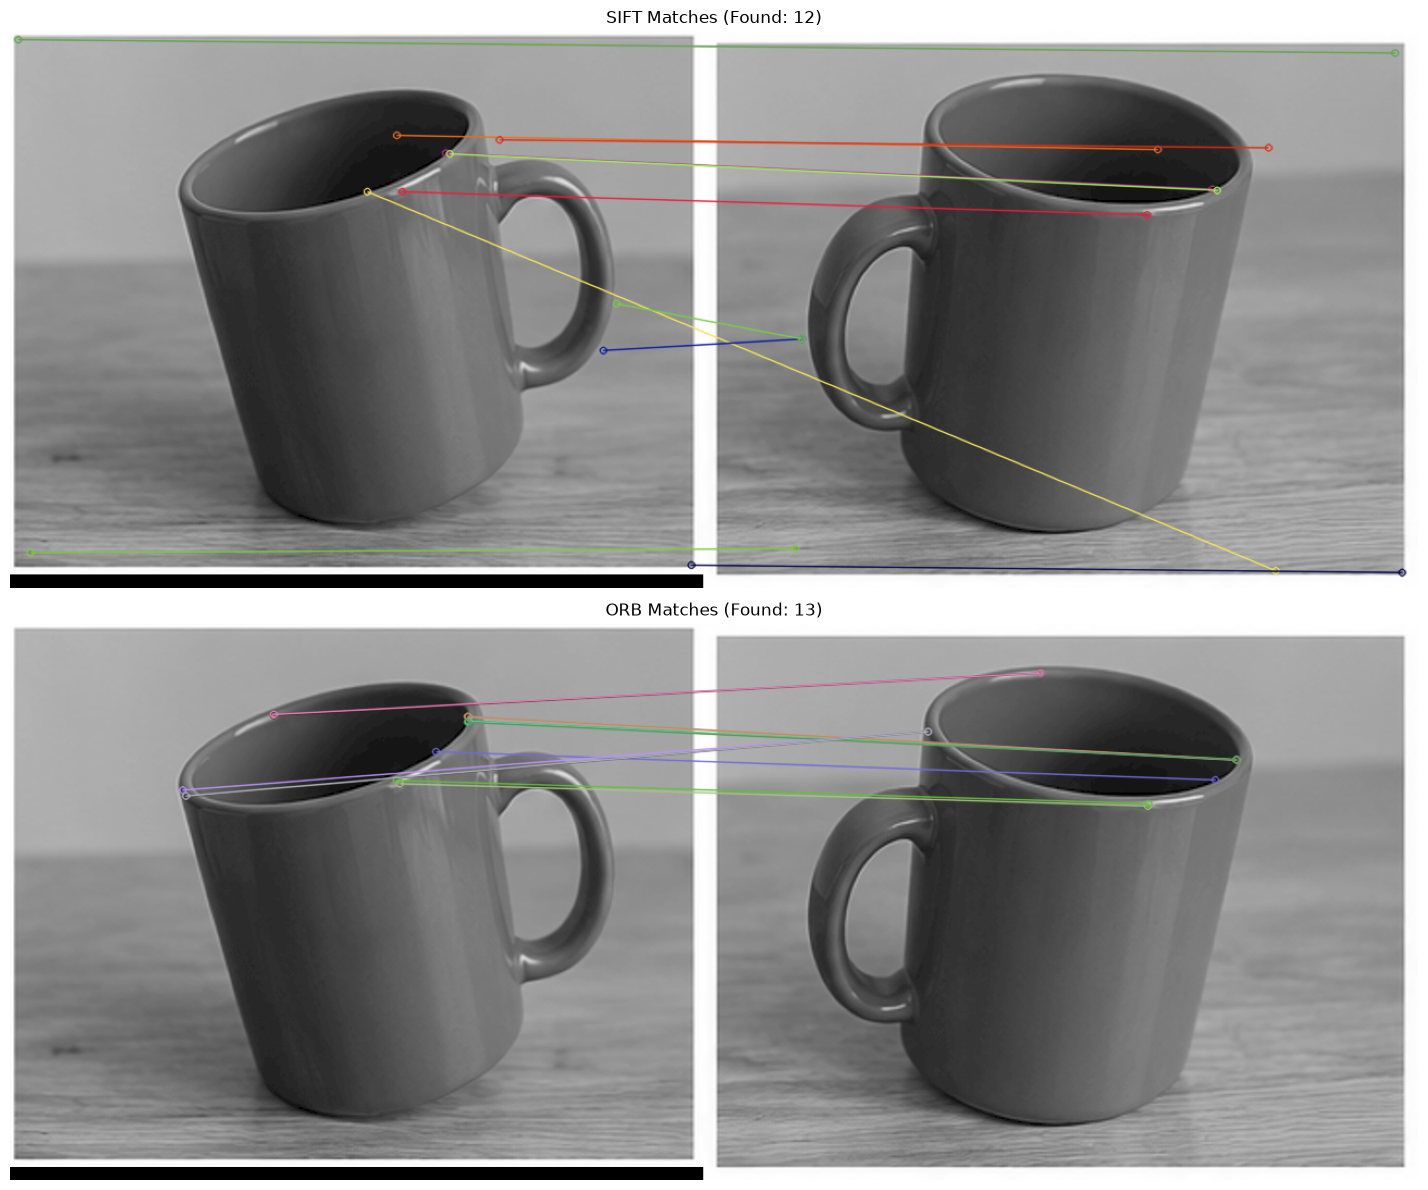

In [13]:
import cv2
import matplotlib.pyplot as plt


# 1. Read the two images (
img1 = cv2.imread('image1.png', cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread('image2.png', cv2.IMREAD_GRAYSCALE)


#  SIFT 
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
kp1_sift, des1_sift = sift.detectAndCompute(img1, None)
kp2_sift, des2_sift = sift.detectAndCompute(img2, None)

# Use Brute-Force Matcher with L2 Norm (Euclidean distance for SIFT)
bf_sift = cv2.BFMatcher(cv2.NORM_L2)
# k=2 returns the 2 best matches for each keypoint (required for Ratio Test)
matches_sift = bf_sift.knnMatch(des1_sift, des2_sift, k=2)

# Apply Lowe's Ratio Test to keep only high-quality matches
good_matches_sift = []
for m, n in matches_sift:
    if m.distance < 0.75 * n.distance:
        good_matches_sift.append(m)

# Draw the SIFT matches
img_matches_sift = cv2.drawMatches(
    img1, kp1_sift, img2, kp2_sift, good_matches_sift, None, 
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)


#  ORB 
orb = cv2.ORB_create(nfeatures=1000) # Limit to top 1000 features

# Detect keypoints and compute descriptors
kp1_orb, des1_orb = orb.detectAndCompute(img1, None)
kp2_orb, des2_orb = orb.detectAndCompute(img2, None)

# Use Brute-Force Matcher with Hamming Distance (for binary descriptors)
bf_orb = cv2.BFMatcher(cv2.NORM_HAMMING)
matches_orb = bf_orb.knnMatch(des1_orb, des2_orb, k=2)

# Apply Lowe's Ratio Test for ORB
good_matches_orb = []
for m, n in matches_orb:
    if m.distance < 0.75 * n.distance:
        good_matches_orb.append(m)

# Draw the ORB matches
img_matches_orb = cv2.drawMatches(
    img1, kp1_orb, img2, kp2_orb, good_matches_orb, None, 
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)


fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# Plot 1: SIFT Matches
axes[0].imshow(img_matches_sift, cmap='gray')
axes[0].set_title(f"SIFT Matches (Found: {len(good_matches_sift)})")
axes[0].axis('off')

# Plot 2: ORB Matches
axes[1].imshow(img_matches_orb, cmap='gray')
axes[1].set_title(f"ORB Matches (Found: {len(good_matches_orb)})")
axes[1].axis('off')

plt.tight_layout()
plt.show()




**1. Number of Keypoints:**

* **SIFT:** Detects a very high number of dense keypoints. Because it uses the Difference of Gaussians (DoG) to search exhaustively across multiple scale spaces (image blur levels), it extracts highly detailed structural points.
* **ORB:** Generally detects fewer keypoints. It relies on the FAST algorithm, which strictly looks for distinct corners based on simple pixel intensity comparisons, rather than dense multi-scale structures.

**2. Number of Matches:**

* **SIFT:** Yields a high volume of matches. Its 128-dimensional floating-point descriptors are highly descriptive, allowing the Brute-Force matcher to find many confident correspondences across the two images.
* **ORB:** Yields fewer raw matches. Since its descriptors are simple binary strings (sequences of 1s and 0s), many keypoints may share similar binary patterns, causing them to be rejected as ambiguous matches during Lowe's Ratio Test.

**3. Quality of Matches:**

* **SIFT:** Exhibits extremely high-quality matches. It is robust and mathematically invariant to both rotation and significant scale changes (meaning the object can be much larger or smaller in the second image). It is ideal for complex tasks like 3D reconstruction.
* **ORB:** Exhibits moderate-to-high quality matches. It handles image rotation effectively and is highly resistant to noise. However, it lacks true scale invariance. If the object in the second image is significantly scaled up or down compared to the first, ORB's match quality drops drastically compared to SIFT.